# HW7 Mini Project — Your IFR Interpolator

Design your own interpolator. For compatible data, it should be continuous, pass through the
supplied IFR points, and be **monotone and convex within the node interval**. Explain your choice
of method and how you handle data that cannot satisfy all these conditions.

You may consult **Hagan and West's method** for inspiration.

### Implement your subclass

Write your class in `fixedincomelib/utilities/numerics.py`, inheriting from `Interpolator1D`.
Implement `interpolate` and `integrate`; leave the two optional gradient stubs as supplied.
The `MONOTONE_CONVEX` entry in `InterpMethod` and its factory mapping to
`Interpolator1DMonotoneConvex` are supplied. The one-node funding curve must be constant.

Each cell gives the product terms explicitly and calls the existing library APIs directly.
Within each pair, change only `'interpolation method'` from
`'PIECEWISE_CONSTANT_LEFT_CONTINUOUS'` to `'MONOTONE_CONVEX'`; rebuilding the model selects
your class. Compare the PVs and briefly explain the differences. Use `FLAT` extrapolation
and the supplied IFR data; no calibration is needed.

Cell 1 includes the shared imports and data. Run cells **1, 3, 5** for the PCP results;
after completing your implementation, restart the kernel and run all six.



In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from fixedincomelib.date import Date, accrued
from fixedincomelib.utilities import (
    ExtrapMethod, InterpMethod, InterpolatorFactory,
)
from fixedincomelib import (
    qfCreateData1D, qfCreateDataCollection,
    qfCreateBuildMethod, qfCreateModelBuildMethodCollection, qfCreateModel,
    qfCreateProductFRA, qfCreateProductRFRSwap, qfCreateProductOvernightIndexBasisSwap,
    qfCreateValuationParameters, qfCreateValuationParametersCollection,
    qfCreateValueReport,
)

# Supplied IFR point values, in annual decimals.
node_dates = ["2026-04-02", "2026-10-02", "2027-07-02",
              "2028-01-03", "2029-01-02", "2031-01-02"]
sofr_quotes = pd.DataFrame({"values": [0.025, 0.026, 0.028, 0.030, 0.035, 0.047]}, index=node_dates)
ff_quotes = pd.DataFrame({"values": [0.023, 0.0237, 0.0252, 0.0265, 0.0305, 0.0405]}, index=node_dates)
funding_quotes = pd.DataFrame({"values": [0.0005]}, index=["2027-01-04"])
data_collection = qfCreateDataCollection([
    qfCreateData1D("INSTANTANEOUS FORWARD RATE", "SOFR-1B-IFR", sofr_quotes),
    qfCreateData1D("INSTANTANEOUS FORWARD RATE", "FF-1B-IFR", ff_quotes),
    qfCreateData1D("INSTANTANEOUS FORWARD RATE", "SOFR-1B-FUNDING-IFR", funding_quotes),
])
curve_inputs = [
    ("YIELD_CURVE_INDEX", {"TARGET": "SOFR-1B", "INSTANTANEOUS FORWARD RATE": "SOFR-1B-IFR"}),
    ("YIELD_CURVE_INDEX", {"TARGET": "FF-1B", "INSTANTANEOUS FORWARD RATE": "FF-1B-IFR"}),
    ("YIELD_CURVE_FUNDING", {"TARGET": "SOFR-1B-FLAT", "REFERENCE INDEX": "SOFR-1B",
                            "INSTANTANEOUS FORWARD RATE": "SOFR-1B-FUNDING-IFR"}),
]


### IFR curve and shape constraints

I use a local quadratic Bezier curve on every node interval. PCHIP-style local slope estimates propose the Bezier control ordinate, which is then projected into the interval from the lower endpoint to the chord midpoint. This projection makes the derivative keep the sign of the endpoint change (monotonicity) and makes the second derivative non-negative (convexity). The curve is continuous and exactly reproduces every supplied IFR point.

If the nodes reverse direction, global monotonicity is mathematically impossible while retaining exact node fit. In that case the method preserves the direction of each individual interval and permits a turning point at the node. If neighbouring slopes are incompatible with positive curvature, the control point is projected to the chord midpoint, so that interval safely degenerates to a straight line. Derivative continuity is therefore relaxed before node fit, C0 continuity, monotonicity, or convexity. A one-node curve and all extrapolation are flat.

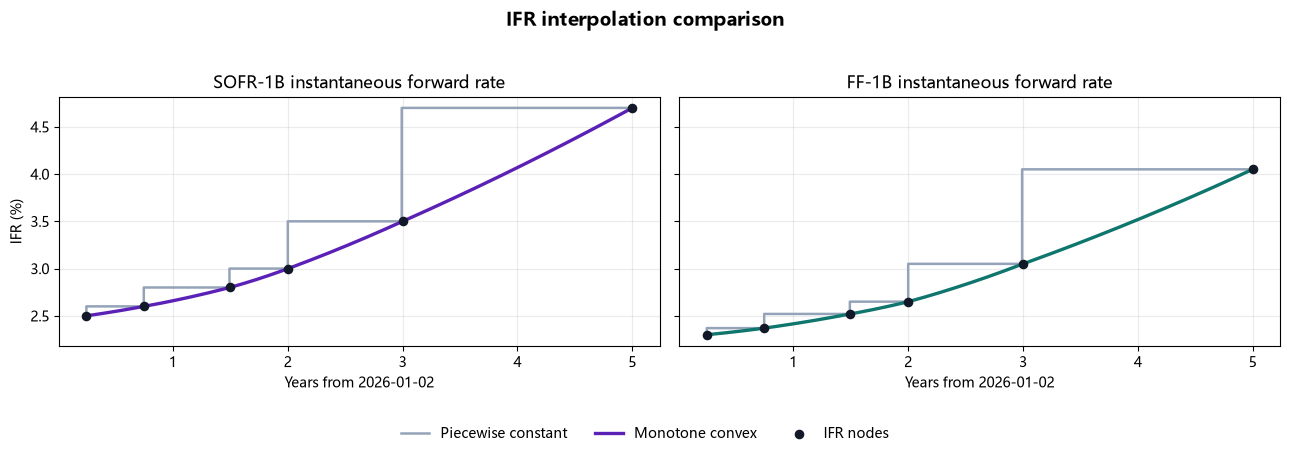

In [2]:
value_date = Date("2026-01-02")
node_times = np.array([accrued(value_date, Date(d)) for d in node_dates])
grid = np.linspace(node_times[0], node_times[-1], 600)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, label, quotes, color in [
    (axes[0], "SOFR-1B", sofr_quotes, "#5b21b6"),
    (axes[1], "FF-1B", ff_quotes, "#0f766e"),
]:
    values = quotes["values"].to_numpy(dtype=float)
    pcp = InterpolatorFactory.create_1d_interpolator(
        node_times, values, InterpMethod.PIECEWISE_CONSTANT_LEFT_CONTINUOUS, ExtrapMethod.FLAT
    )
    mc = InterpolatorFactory.create_1d_interpolator(
        node_times, values, InterpMethod.MONOTONE_CONVEX, ExtrapMethod.FLAT
    )
    pcp_values = np.array([pcp.interpolate(x) for x in grid])
    mc_values = np.array([mc.interpolate(x) for x in grid])

    # Exact node reproduction and dense shape checks on every interval.
    assert np.allclose([mc.interpolate(x) for x in node_times], values)
    for left, right in zip(node_times[:-1], node_times[1:]):
        interval_grid = np.linspace(left, right, 101)
        interval_values = np.array([mc.interpolate(x) for x in interval_grid])
        assert np.all(np.diff(interval_values) >= -1e-12)
        assert np.all(np.diff(interval_values, n=2) >= -1e-12)

    ax.step(grid, 100 * pcp_values, where="pre", color="#94a3b8", lw=1.8,
            label="Piecewise constant")
    ax.plot(grid, 100 * mc_values, color=color, lw=2.4, label="Monotone convex")
    ax.scatter(node_times, 100 * values, color="#111827", s=35, zorder=3, label="IFR nodes")
    ax.set_title(f"{label} instantaneous forward rate")
    ax.set_xlabel("Years from 2026-01-02")
    ax.grid(alpha=0.25)

axes[0].set_ylabel("IFR (%)")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3, frameon=False)
fig.suptitle("IFR interpolation comparison", fontsize=14, fontweight="bold")
fig.tight_layout(rect=(0, 0.10, 1, 0.95))
plt.show()

In [3]:
# 1. FRA — piecewise constant
fra_pcp_convention = {
    'effective date': '2026-05-05',
    'termination date': '2026-11-05',
    'projection index': 'SOFR-1B',
    'fixed rate': 0.032,
    'notional': 1000000,
    'pay or receive': 'receive',
    'accrual basis': 'ACT/360',
    'business day convention': 'F',
    'holiday convention': 'USGS',
    'value date': '2026-01-02',
    'funding index': 'SOFR-1B-FLAT',
    'interpolation method': 'PIECEWISE_CONSTANT_LEFT_CONTINUOUS',
    'extrapolation method': 'FLAT',
}

build_methods = qfCreateModelBuildMethodCollection([
    qfCreateBuildMethod(kind, {
        **inputs,
        "INTERPOLATION METHOD": fra_pcp_convention["interpolation method"],
        "EXTRAPOLATION METHOD": fra_pcp_convention["extrapolation method"],
    }) for kind, inputs in curve_inputs
])
fra_pcp_model = qfCreateModel(
    fra_pcp_convention["value date"], "YIELD_CURVE", data_collection, build_methods,
)
fra_pcp_product = qfCreateProductFRA(
    effective_date=fra_pcp_convention['effective date'],
    term_or_termination_date=fra_pcp_convention['termination date'],
    projection_index=fra_pcp_convention['projection index'],
    fixed_rate=fra_pcp_convention['fixed rate'],
    notional=fra_pcp_convention['notional'],
    pay_or_rec=fra_pcp_convention['pay or receive'],
    accrual_basis=fra_pcp_convention['accrual basis'],
    business_day_convention=fra_pcp_convention['business day convention'],
    holiday_convention=fra_pcp_convention['holiday convention'],
)
fra_pcp_parameters = qfCreateValuationParametersCollection([
    qfCreateValuationParameters("FUNDING INDEX PARAMETER", {
        "FUNDING INDEX": fra_pcp_convention["funding index"],
    }),
])
fra_pcp_pv = qfCreateValueReport(fra_pcp_model, fra_pcp_product, fra_pcp_parameters, "PV")[0][1]
print("FRA | PCP PV:", fra_pcp_pv)


FRA | PCP PV: 2908.2866392379638


In [4]:
# 2. FRA — your interpolator
fra_student_convention = {
    'effective date': '2026-05-05',
    'termination date': '2026-11-05',
    'projection index': 'SOFR-1B',
    'fixed rate': 0.032,
    'notional': 1000000,
    'pay or receive': 'receive',
    'accrual basis': 'ACT/360',
    'business day convention': 'F',
    'holiday convention': 'USGS',
    'value date': '2026-01-02',
    'funding index': 'SOFR-1B-FLAT',
    'interpolation method': 'MONOTONE_CONVEX',
    'extrapolation method': 'FLAT',
}

build_methods = qfCreateModelBuildMethodCollection([
    qfCreateBuildMethod(kind, {
        **inputs,
        "INTERPOLATION METHOD": fra_student_convention["interpolation method"],
        "EXTRAPOLATION METHOD": fra_student_convention["extrapolation method"],
    }) for kind, inputs in curve_inputs
])
fra_student_model = qfCreateModel(
    fra_student_convention["value date"], "YIELD_CURVE", data_collection, build_methods,
)
fra_student_product = qfCreateProductFRA(
    effective_date=fra_student_convention['effective date'],
    term_or_termination_date=fra_student_convention['termination date'],
    projection_index=fra_student_convention['projection index'],
    fixed_rate=fra_student_convention['fixed rate'],
    notional=fra_student_convention['notional'],
    pay_or_rec=fra_student_convention['pay or receive'],
    accrual_basis=fra_student_convention['accrual basis'],
    business_day_convention=fra_student_convention['business day convention'],
    holiday_convention=fra_student_convention['holiday convention'],
)
fra_student_parameters = qfCreateValuationParametersCollection([
    qfCreateValuationParameters("FUNDING INDEX PARAMETER", {
        "FUNDING INDEX": fra_student_convention["funding index"],
    }),
])
fra_student_pv = qfCreateValueReport(fra_student_model, fra_student_product, fra_student_parameters, "PV")[0][1]
print("FRA | Student PV:", fra_student_pv)
print("Student minus PCP:", fra_student_pv - fra_pcp_pv)


FRA | Student PV: 3261.902776757659
Student minus PCP: 353.61613751969526


In [5]:
# 3. RFR swap — piecewise constant
swap_pcp_convention = {
    'effective date': '2026-04-02',
    'termination date': '2029-04-02',
    'overnight index': 'SOFR-1B',
    'fixed rate': 0.034,
    'notional': 1000000,
    'pay or receive': 'receive',
    'fixed accrual period': '1Y',
    'floating accrual period': '1Y',
    'accrual basis': 'ACT/360',
    'compounding method': 'compound',
    'floating spread': 0.0,
    'payment offset': '2D',
    'payment business day convention': 'F',
    'payment holiday convention': 'USGS',
    'value date': '2026-01-02',
    'funding index': 'SOFR-1B-FLAT',
    'interpolation method': 'PIECEWISE_CONSTANT_LEFT_CONTINUOUS',
    'extrapolation method': 'FLAT',
}

build_methods = qfCreateModelBuildMethodCollection([
    qfCreateBuildMethod(kind, {
        **inputs,
        "INTERPOLATION METHOD": swap_pcp_convention["interpolation method"],
        "EXTRAPOLATION METHOD": swap_pcp_convention["extrapolation method"],
    }) for kind, inputs in curve_inputs
])
swap_pcp_model = qfCreateModel(
    swap_pcp_convention["value date"], "YIELD_CURVE", data_collection, build_methods,
)
swap_pcp_product = qfCreateProductRFRSwap(
    effective_date=swap_pcp_convention['effective date'],
    term_or_termination_date=swap_pcp_convention['termination date'],
    on_index=swap_pcp_convention['overnight index'],
    fixed_rate=swap_pcp_convention['fixed rate'],
    notional=swap_pcp_convention['notional'],
    pay_or_rec=swap_pcp_convention['pay or receive'],
    accrual_period=swap_pcp_convention['fixed accrual period'],
    floating_leg_accrual_period=swap_pcp_convention['floating accrual period'],
    accrual_basis=swap_pcp_convention['accrual basis'],
    compounding_method=swap_pcp_convention['compounding method'],
    spread=swap_pcp_convention['floating spread'],
    payment_off_set=swap_pcp_convention['payment offset'],
    pay_business_day_convention=swap_pcp_convention['payment business day convention'],
    pay_holiday_convention=swap_pcp_convention['payment holiday convention'],
)
swap_pcp_parameters = qfCreateValuationParametersCollection([
    qfCreateValuationParameters("FUNDING INDEX PARAMETER", {
        "FUNDING INDEX": swap_pcp_convention["funding index"],
    }),
])
swap_pcp_pv = qfCreateValueReport(swap_pcp_model, swap_pcp_product, swap_pcp_parameters, "PV")[0][1]
print("RFR swap | PCP PV:", swap_pcp_pv)


RFR swap | PCP PV: 6222.517513070357


In [6]:
# 4. RFR swap — your interpolator
swap_student_convention = {
    'effective date': '2026-04-02',
    'termination date': '2029-04-02',
    'overnight index': 'SOFR-1B',
    'fixed rate': 0.034,
    'notional': 1000000,
    'pay or receive': 'receive',
    'fixed accrual period': '1Y',
    'floating accrual period': '1Y',
    'accrual basis': 'ACT/360',
    'compounding method': 'compound',
    'floating spread': 0.0,
    'payment offset': '2D',
    'payment business day convention': 'F',
    'payment holiday convention': 'USGS',
    'value date': '2026-01-02',
    'funding index': 'SOFR-1B-FLAT',
    'interpolation method': 'MONOTONE_CONVEX',
    'extrapolation method': 'FLAT',
}

build_methods = qfCreateModelBuildMethodCollection([
    qfCreateBuildMethod(kind, {
        **inputs,
        "INTERPOLATION METHOD": swap_student_convention["interpolation method"],
        "EXTRAPOLATION METHOD": swap_student_convention["extrapolation method"],
    }) for kind, inputs in curve_inputs
])
swap_student_model = qfCreateModel(
    swap_student_convention["value date"], "YIELD_CURVE", data_collection, build_methods,
)
swap_student_product = qfCreateProductRFRSwap(
    effective_date=swap_student_convention['effective date'],
    term_or_termination_date=swap_student_convention['termination date'],
    on_index=swap_student_convention['overnight index'],
    fixed_rate=swap_student_convention['fixed rate'],
    notional=swap_student_convention['notional'],
    pay_or_rec=swap_student_convention['pay or receive'],
    accrual_period=swap_student_convention['fixed accrual period'],
    floating_leg_accrual_period=swap_student_convention['floating accrual period'],
    accrual_basis=swap_student_convention['accrual basis'],
    compounding_method=swap_student_convention['compounding method'],
    spread=swap_student_convention['floating spread'],
    payment_off_set=swap_student_convention['payment offset'],
    pay_business_day_convention=swap_student_convention['payment business day convention'],
    pay_holiday_convention=swap_student_convention['payment holiday convention'],
)
swap_student_parameters = qfCreateValuationParametersCollection([
    qfCreateValuationParameters("FUNDING INDEX PARAMETER", {
        "FUNDING INDEX": swap_student_convention["funding index"],
    }),
])
swap_student_pv = qfCreateValueReport(swap_student_model, swap_student_product, swap_student_parameters, "PV")[0][1]
print("RFR swap | Student PV:", swap_student_pv)
print("Student minus PCP:", swap_student_pv - swap_pcp_pv)


RFR swap | Student PV: 12856.497480024176
Student minus PCP: 6633.979966953819


In [7]:
# 5. Overnight basis swap — piecewise constant
basis_pcp_convention = {
    'effective date': '2026-07-02',
    'termination date': '2028-07-03',
    'overnight index leg 1': 'SOFR-1B',
    'overnight index leg 2': 'FF-1B',
    'spread over leg 1': 0.001,
    'notional': 1000000,
    'pay or receive leg 1': 'receive',
    'accrual period leg 1': '3M',
    'accrual period leg 2': '3M',
    'accrual basis': 'ACT/360',
    'compounding method': 'compound',
    'payment offset': '2D',
    'payment business day convention': 'F',
    'payment holiday convention': 'USGS',
    'value date': '2026-01-02',
    'funding index': 'SOFR-1B-FLAT',
    'interpolation method': 'PIECEWISE_CONSTANT_LEFT_CONTINUOUS',
    'extrapolation method': 'FLAT',
}

build_methods = qfCreateModelBuildMethodCollection([
    qfCreateBuildMethod(kind, {
        **inputs,
        "INTERPOLATION METHOD": basis_pcp_convention["interpolation method"],
        "EXTRAPOLATION METHOD": basis_pcp_convention["extrapolation method"],
    }) for kind, inputs in curve_inputs
])
basis_pcp_model = qfCreateModel(
    basis_pcp_convention["value date"], "YIELD_CURVE", data_collection, build_methods,
)
basis_pcp_product = qfCreateProductOvernightIndexBasisSwap(
    effective_date=basis_pcp_convention['effective date'],
    term_or_termination_date=basis_pcp_convention['termination date'],
    on_index_leg_1=basis_pcp_convention['overnight index leg 1'],
    on_index_leg_2=basis_pcp_convention['overnight index leg 2'],
    spread_over_leg_1=basis_pcp_convention['spread over leg 1'],
    notional=basis_pcp_convention['notional'],
    pay_or_rec_leg_1=basis_pcp_convention['pay or receive leg 1'],
    accrual_period_1=basis_pcp_convention['accrual period leg 1'],
    accrual_period_2=basis_pcp_convention['accrual period leg 2'],
    accrual_basis=basis_pcp_convention['accrual basis'],
    compounding_method=basis_pcp_convention['compounding method'],
    payment_off_set=basis_pcp_convention['payment offset'],
    pay_business_day_convention=basis_pcp_convention['payment business day convention'],
    pay_holiday_convention=basis_pcp_convention['payment holiday convention'],
)
basis_pcp_parameters = qfCreateValuationParametersCollection([
    qfCreateValuationParameters("FUNDING INDEX PARAMETER", {
        "FUNDING INDEX": basis_pcp_convention["funding index"],
    }),
])
basis_pcp_pv = qfCreateValueReport(basis_pcp_model, basis_pcp_product, basis_pcp_parameters, "PV")[0][1]
print("Overnight basis swap | PCP PV:", basis_pcp_pv)


Overnight basis swap | PCP PV: 8351.348908181775


In [8]:
# 6. Overnight basis swap — your interpolator
basis_student_convention = {
    'effective date': '2026-07-02',
    'termination date': '2028-07-03',
    'overnight index leg 1': 'SOFR-1B',
    'overnight index leg 2': 'FF-1B',
    'spread over leg 1': 0.001,
    'notional': 1000000,
    'pay or receive leg 1': 'receive',
    'accrual period leg 1': '3M',
    'accrual period leg 2': '3M',
    'accrual basis': 'ACT/360',
    'compounding method': 'compound',
    'payment offset': '2D',
    'payment business day convention': 'F',
    'payment holiday convention': 'USGS',
    'value date': '2026-01-02',
    'funding index': 'SOFR-1B-FLAT',
    'interpolation method': 'MONOTONE_CONVEX',
    'extrapolation method': 'FLAT',
}

build_methods = qfCreateModelBuildMethodCollection([
    qfCreateBuildMethod(kind, {
        **inputs,
        "INTERPOLATION METHOD": basis_student_convention["interpolation method"],
        "EXTRAPOLATION METHOD": basis_student_convention["extrapolation method"],
    }) for kind, inputs in curve_inputs
])
basis_student_model = qfCreateModel(
    basis_student_convention["value date"], "YIELD_CURVE", data_collection, build_methods,
)
basis_student_product = qfCreateProductOvernightIndexBasisSwap(
    effective_date=basis_student_convention['effective date'],
    term_or_termination_date=basis_student_convention['termination date'],
    on_index_leg_1=basis_student_convention['overnight index leg 1'],
    on_index_leg_2=basis_student_convention['overnight index leg 2'],
    spread_over_leg_1=basis_student_convention['spread over leg 1'],
    notional=basis_student_convention['notional'],
    pay_or_rec_leg_1=basis_student_convention['pay or receive leg 1'],
    accrual_period_1=basis_student_convention['accrual period leg 1'],
    accrual_period_2=basis_student_convention['accrual period leg 2'],
    accrual_basis=basis_student_convention['accrual basis'],
    compounding_method=basis_student_convention['compounding method'],
    payment_off_set=basis_student_convention['payment offset'],
    pay_business_day_convention=basis_student_convention['payment business day convention'],
    pay_holiday_convention=basis_student_convention['payment holiday convention'],
)
basis_student_parameters = qfCreateValuationParametersCollection([
    qfCreateValuationParameters("FUNDING INDEX PARAMETER", {
        "FUNDING INDEX": basis_student_convention["funding index"],
    }),
])
basis_student_pv = qfCreateValueReport(basis_student_model, basis_student_product, basis_student_parameters, "PV")[0][1]
print("Overnight basis swap | Student PV:", basis_student_pv)
print("Student minus PCP:", basis_student_pv - basis_pcp_pv)


Overnight basis swap | Student PV: 7628.303757898189
Student minus PCP: -723.0451502835858


### PV comparison and interpretation

| Product | Piecewise-constant PV | Monotone-convex PV | MC - PCP |
|---|---:|---:|---:|
| FRA | 2,908.29 | 3,261.90 | 353.62 |
| RFR swap | 6,222.52 | 12,856.50 | 6,633.98 |
| Overnight basis swap | 8,351.35 | 7,628.30 | -723.05 |

The interpolators agree at the supplied IFR nodes but assign different rates between them. The FRA covers a short section of the SOFR curve, so its difference is modest. The three-year RFR swap compounds and discounts cash flows across several intervals; the smoother curve therefore changes its cumulative projected floating return materially. The basis swap depends on both the SOFR and Federal Funds curves, so changes in the two legs partly offset and the sign need not match the single-curve products. These are interpolation effects only: product terms, input nodes, extrapolation and funding assumptions are unchanged.